<a href="https://colab.research.google.com/github/Maryam-Yaqoob/ANN-LAB/blob/main/FA23_BAI_025___Lab_Mid_Iris_MLP_Ablation___Maryam_Yaqoob.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Lab Mid — Ablation Study of Regularization Techniques in an MLP (Iris Dataset)

**Student:** Maryam Yaqoob (FA23-BAI-025) · **University:** COMSATS University Islamabad  
**Lab Instructor:** Zaeem Akbar Khan

**Goal:** Train an MLP to classify Iris flowers (Setosa / Versicolor / Virginica) and run a controlled ablation study over weight initialization, L2 regularization, dropout and learning rate, with identical early stopping for every experiment.

### Assumptions (flagged explicitly)
| # | Assumption | Reason |
|---|---|---|
| A1 | Optimizer = **Adam**, batch size = **16** (fixed for all experiments) | Not specified in the paper; only the learning rate is varied |
| A2 | Hidden activation = **ReLU** | Not specified; standard with He initialization |
| A3 | L2 penalty is applied to the **kernel weights of the two hidden layers** (not biases, not the output layer) | Common convention; same for all L2 experiments |
| A4 | Dropout is applied **after each hidden layer** | Standard placement |
| A5 | The chosen initializer (Glorot uniform / He normal) is used for **all Dense layers** | Keeps the initialization factor consistent |
| A6 | Split uses `random_state=42` and is **identical** for all experiments and seeds; only the *training* seed changes | Fair comparison, as required |
| A7 | **5 seeds** per experiment (≥ 3 required); results reported as mean ± std | Reduces the noise of a 30-sample test set |
| A8 | Keras `val_loss` (monitored by early stopping) includes the L2 penalty term, so it is not directly comparable across L2/non-L2 runs. **Test loss is therefore reported as pure cross-entropy** (computed separately) for fairness | Otherwise L2 runs would look artificially worse |


In [1]:
import os, time, random, warnings
warnings.filterwarnings("ignore")
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"
os.makedirs("figures", exist_ok=True)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, regularizers, callbacks

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, f1_score, log_loss, confusion_matrix

pd.set_option("display.width", 200)
sns.set_theme(style="whitegrid")
print("TensorFlow:", tf.__version__)

TensorFlow: 2.21.0


## 1. Data loading, stratified split and scaling

In [2]:
iris = load_iris()
X, y = iris.data, iris.target
class_names = list(iris.target_names)
print("X:", X.shape, "| y:", y.shape, "| classes:", class_names)

SPLIT_SEED = 42
# 60% train / 40% temp, then temp -> 20% val / 20% test (both stratified)
X_train, X_tmp, y_train, y_tmp = train_test_split(X, y, test_size=0.40, stratify=y, random_state=SPLIT_SEED)
X_val, X_test, y_val, y_test   = train_test_split(X_tmp, y_tmp, test_size=0.50, stratify=y_tmp, random_state=SPLIT_SEED)

# Scaler fitted ONLY on the training set (no data leakage)
scaler = StandardScaler().fit(X_train)
X_train_s, X_val_s, X_test_s = scaler.transform(X_train), scaler.transform(X_val), scaler.transform(X_test)

print("Train/Val/Test sizes:", len(X_train_s), len(X_val_s), len(X_test_s))
print("Class counts  train:", np.bincount(y_train), " val:", np.bincount(y_val), " test:", np.bincount(y_test))
print("Train mean ~0:", X_train_s.mean(0).round(3), " std ~1:", X_train_s.std(0).round(3))

X: (150, 4) | y: (150,) | classes: [np.str_('setosa'), np.str_('versicolor'), np.str_('virginica')]
Train/Val/Test sizes: 90 30 30
Class counts  train: [30 30 30]  val: [10 10 10]  test: [10 10 10]
Train mean ~0: [-0. -0. -0.  0.]  std ~1: [1. 1. 1. 1.]


## 2. Model, experiment configuration and training function
Architecture is fixed: `Input(4) → Dense(64, ReLU) → [Dropout] → Dense(32, ReLU) → [Dropout] → Dense(3, softmax)`.  
Early stopping (same for every run): monitor `val_loss`, patience 15, `restore_best_weights=True`, max 200 epochs.

In [3]:
MAX_EPOCHS, PATIENCE, BATCH_SIZE = 200, 15, 16
SEEDS = [42, 7, 123, 2024, 99]          # 5 training seeds (>= 3 required)

EXPERIMENTS = {
    "E0: Baseline":       dict(init="glorot_uniform", l2=0.0,  dropout=0.0, lr=1e-3),
    "E1: Initialization": dict(init="he_normal",      l2=0.0,  dropout=0.0, lr=1e-3),
    "E2: L2":             dict(init="glorot_uniform", l2=0.01, dropout=0.0, lr=1e-3),
    "E3: Dropout":        dict(init="glorot_uniform", l2=0.0,  dropout=0.3, lr=1e-3),
    "E4: Combined":       dict(init="glorot_uniform", l2=0.01, dropout=0.3, lr=1e-3),
    "E5: Low LR":         dict(init="glorot_uniform", l2=0.01, dropout=0.3, lr=1e-4),
    "E6: High LR":        dict(init="glorot_uniform", l2=0.01, dropout=0.3, lr=1e-2),
}
pd.DataFrame(EXPERIMENTS).T

,init,l2,dropout,lr
E0: Baseline,glorot_uniform,0.0,0.0,0.001
E1: Initialization,he_normal,0.0,0.0,0.001
E2: L2,glorot_uniform,0.01,0.0,0.001
E3: Dropout,glorot_uniform,0.0,0.3,0.001
E4: Combined,glorot_uniform,0.01,0.3,0.001
E5: Low LR,glorot_uniform,0.01,0.3,0.0001
E6: High LR,glorot_uniform,0.01,0.3,0.01


In [4]:
def build_model(init, l2, dropout, lr):
    reg = regularizers.l2(l2) if l2 > 0 else None
    inp = keras.Input(shape=(4,))
    x = layers.Dense(64, activation="relu", kernel_initializer=init, kernel_regularizer=reg)(inp)
    if dropout > 0: x = layers.Dropout(dropout)(x)
    x = layers.Dense(32, activation="relu", kernel_initializer=init, kernel_regularizer=reg)(x)
    if dropout > 0: x = layers.Dropout(dropout)(x)
    out = layers.Dense(3, activation="softmax", kernel_initializer=init)(x)
    model = keras.Model(inp, out)
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=lr),
                  loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return model

def run_experiment(name, cfg, seed):
    keras.utils.set_random_seed(seed)           # python + numpy + TF seeds
    model = build_model(**cfg)
    es = callbacks.EarlyStopping(monitor="val_loss", patience=PATIENCE, restore_best_weights=True)
    t0 = time.time()
    hist = model.fit(X_train_s, y_train, validation_data=(X_val_s, y_val),
                     epochs=MAX_EPOCHS, batch_size=BATCH_SIZE, callbacks=[es], verbose=0)
    train_time = time.time() - t0

    h = hist.history
    epochs_run = len(h["loss"])
    best_epoch = int(np.argmin(h["val_loss"])) + 1

    # Evaluate with restored best weights. Pure cross-entropy (no L2 term) for a fair test loss.
    def evaluate(Xs, ys):
        p = model.predict(Xs, verbose=0)
        pred = p.argmax(1)
        return (accuracy_score(ys, pred), f1_score(ys, pred, average="macro"),
                log_loss(ys, p, labels=[0, 1, 2]), pred)
    tr_acc, _, tr_ce, _        = evaluate(X_train_s, y_train)
    va_acc, _, va_ce, _        = evaluate(X_val_s, y_val)
    te_acc, te_f1, te_ce, pred = evaluate(X_test_s, y_test)

    return dict(experiment=name, seed=seed, epochs_run=epochs_run, best_epoch=best_epoch,
                train_time_s=train_time, train_acc=tr_acc, val_acc=va_acc, test_acc=te_acc,
                test_macro_f1=te_f1, test_loss=te_ce, train_ce=tr_ce, val_ce=va_ce,
                gap_ce=va_ce - tr_ce), h, pred

## 3. Run all experiments (7 experiments × 5 seeds)

In [5]:
rows, histories, preds = [], {}, {}
for name, cfg in EXPERIMENTS.items():
    for seed in SEEDS:
        r, h, p = run_experiment(name, cfg, seed)
        rows.append(r); histories[(name, seed)] = h; preds[(name, seed)] = p
    sub = pd.DataFrame([r for r in rows if r["experiment"] == name])
    print(f"{name:20s} done | mean test acc = {sub.test_acc.mean():.4f} | mean epochs = {sub.epochs_run.mean():.1f}")

results = pd.DataFrame(rows)
results.to_csv("results_all_runs.csv", index=False)

E0: Baseline         done | mean test acc = 0.9333 | mean epochs = 200.0
E1: Initialization   done | mean test acc = 0.9267 | mean epochs = 176.8
E2: L2               done | mean test acc = 0.9400 | mean epochs = 200.0
E3: Dropout          done | mean test acc = 0.9400 | mean epochs = 153.0
E4: Combined         done | mean test acc = 0.9400 | mean epochs = 193.8
E5: Low LR           done | mean test acc = 0.8800 | mean epochs = 200.0
E6: High LR          done | mean test acc = 0.9667 | mean epochs = 47.0


## 4. Results

In [6]:
summary = results.groupby("experiment", sort=False).agg(
    test_acc=("test_acc", "mean"), test_acc_std=("test_acc", "std"),
    macro_f1=("test_macro_f1", "mean"), macro_f1_std=("test_macro_f1", "std"),
    test_loss=("test_loss", "mean"), test_loss_std=("test_loss", "std"),
    val_acc=("val_acc", "mean"),
    epochs_run=("epochs_run", "mean"), best_epoch=("best_epoch", "mean"),
    train_time_s=("train_time_s", "mean"), gap_ce=("gap_ce", "mean")).round(4)
summary.to_csv("results_summary.csv")
display(summary)

fmt = pd.DataFrame({
    "Test Acc": summary.test_acc.map("{:.3f}".format) + " ± " + summary.test_acc_std.map("{:.3f}".format),
    "Macro F1": summary.macro_f1.map("{:.3f}".format) + " ± " + summary.macro_f1_std.map("{:.3f}".format),
    "Test Loss": summary.test_loss.map("{:.3f}".format) + " ± " + summary.test_loss_std.map("{:.3f}".format),
    "Epochs run": summary.epochs_run.map("{:.1f}".format),
    "Best epoch": summary.best_epoch.map("{:.1f}".format),
    "Time (s)": summary.train_time_s.map("{:.1f}".format)})
fmt.to_csv("results_formatted.csv")
display(fmt)

,test_acc,test_acc_std,macro_f1,macro_f1_std,test_loss,test_loss_std,val_acc,epochs_run,best_epoch,train_time_s,gap_ce
experiment,,,,,,,,,,,
E0: Baseline,0.9333,0.0000,0.9327,0.0000,0.1846,0.0182,0.9467,200.0,198.2,32.3793,0.0828
E1: Initialization,0.9267,0.0149,0.9261,0.0147,0.1961,0.0400,0.9333,176.8,173.8,27.3197,0.1653
E2: L2,0.9400,0.0149,0.9394,0.0152,0.1155,0.0118,0.9400,200.0,200.0,30.4466,0.0419
E3: Dropout,0.9400,0.0149,0.9394,0.0152,0.1158,0.0355,0.9333,153.0,138.0,22.9260,0.0610
E4: Combined,0.9400,0.0149,0.9394,0.0152,0.1174,0.0116,0.9400,193.8,186.2,32.0857,0.0329
E5: Low LR,0.8800,0.0380,0.8778,0.0398,0.3425,0.0199,0.7933,200.0,200.0,32.5165,0.0877
E6: High LR,0.9667,0.0000,0.9666,0.0000,0.0992,0.0154,0.9733,47.0,32.0,8.4232,0.0244


,Test Acc,Macro F1,Test Loss,Epochs run,Best epoch,Time (s)
experiment,,,,,,
E0: Baseline,0.933 ± 0.000,0.933 ± 0.000,0.185 ± 0.018,200.0,198.2,32.4
E1: Initialization,0.927 ± 0.015,0.926 ± 0.015,0.196 ± 0.040,176.8,173.8,27.3
E2: L2,0.940 ± 0.015,0.939 ± 0.015,0.116 ± 0.012,200.0,200.0,30.4
E3: Dropout,0.940 ± 0.015,0.939 ± 0.015,0.116 ± 0.035,153.0,138.0,22.9
E4: Combined,0.940 ± 0.015,0.939 ± 0.015,0.117 ± 0.012,193.8,186.2,32.1
E5: Low LR,0.880 ± 0.038,0.878 ± 0.040,0.343 ± 0.020,200.0,200.0,32.5
E6: High LR,0.967 ± 0.000,0.967 ± 0.000,0.099 ± 0.015,47.0,32.0,8.4


In [7]:
# Per-seed test accuracy (shows the effect of random seed)
display(results.pivot(index="experiment", columns="seed", values="test_acc").loc[list(EXPERIMENTS)])

seed,7,42,99,123,2024
experiment,,,,,
E0: Baseline,0.933333,0.933333,0.933333,0.933333,0.933333
E1: Initialization,0.933333,0.900000,0.933333,0.933333,0.933333
E2: L2,0.966667,0.933333,0.933333,0.933333,0.933333
E3: Dropout,0.966667,0.933333,0.933333,0.933333,0.933333
E4: Combined,0.966667,0.933333,0.933333,0.933333,0.933333
E5: Low LR,0.866667,0.833333,0.866667,0.900000,0.933333
E6: High LR,0.966667,0.966667,0.966667,0.966667,0.966667


## 5. Visualisations

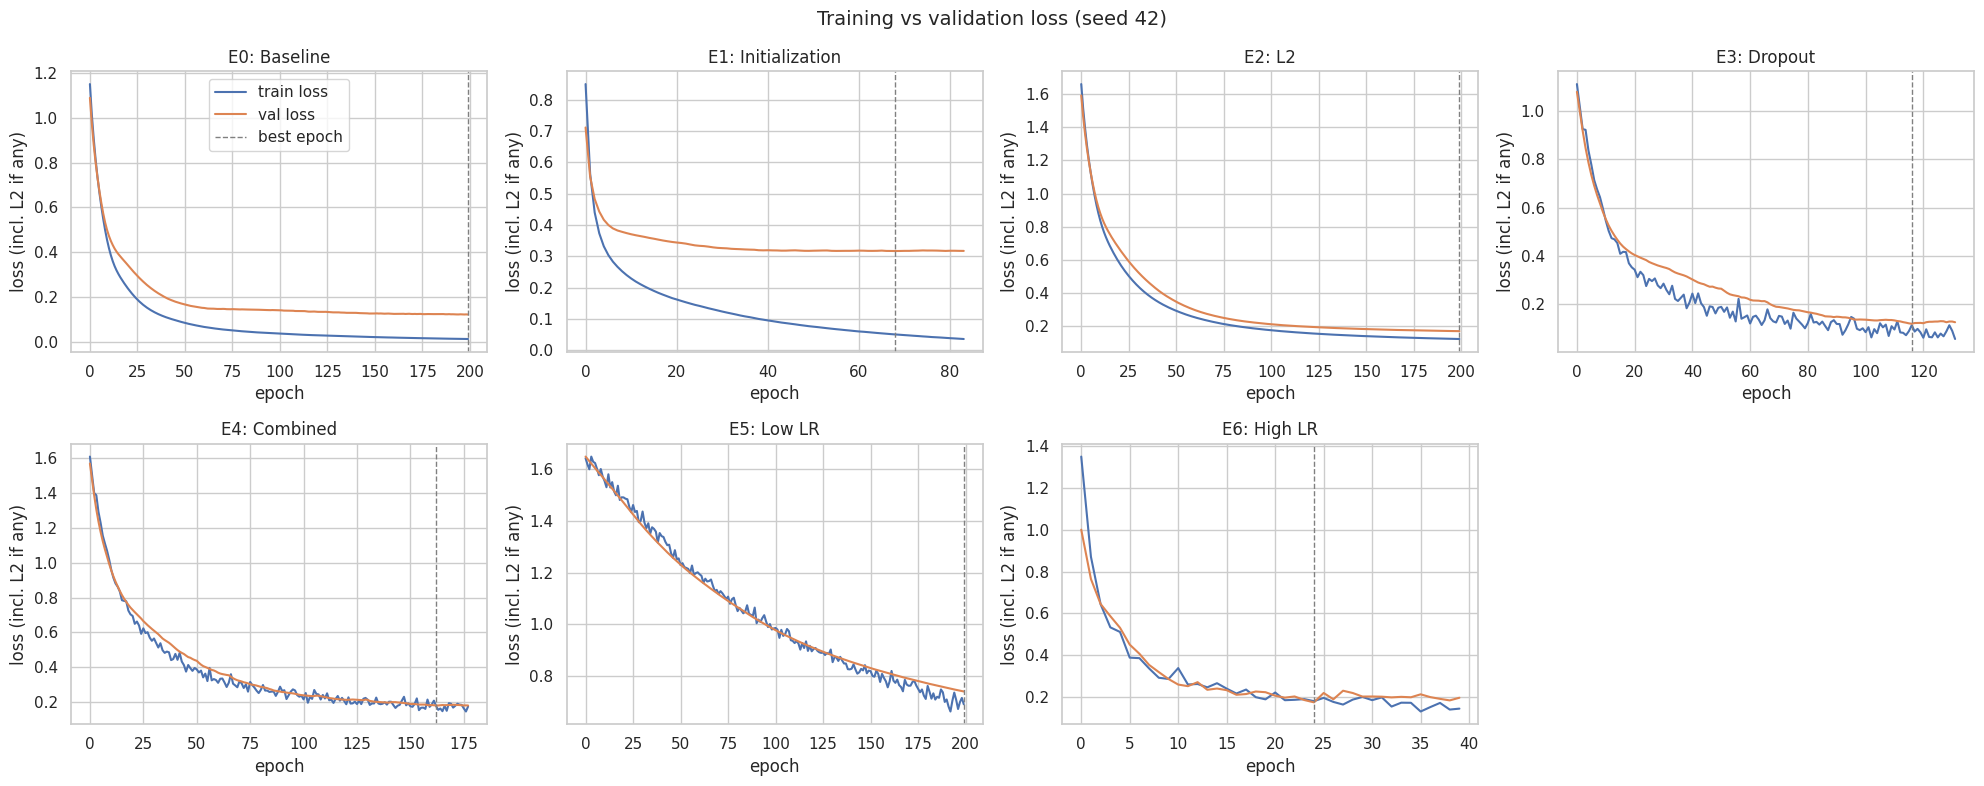

In [8]:
# (a) Learning curves for the first seed, all experiments
seed0 = SEEDS[0]
fig, axes = plt.subplots(2, 4, figsize=(20, 8), sharey=False)
for ax, name in zip(axes.ravel(), EXPERIMENTS):
    h = histories[(name, seed0)]
    ax.plot(h["loss"], label="train loss"); ax.plot(h["val_loss"], label="val loss")
    ax.axvline(int(np.argmin(h["val_loss"])), color="gray", ls="--", lw=1, label="best epoch")
    ax.set_title(name); ax.set_xlabel("epoch"); ax.set_ylabel("loss (incl. L2 if any)")
    if name == "E0: Baseline": ax.legend()
axes.ravel()[-1].axis("off")
plt.suptitle(f"Training vs validation loss (seed {seed0})", fontsize=14)
plt.tight_layout(); plt.savefig("figures/fig1_learning_curves.png", dpi=150); plt.show()

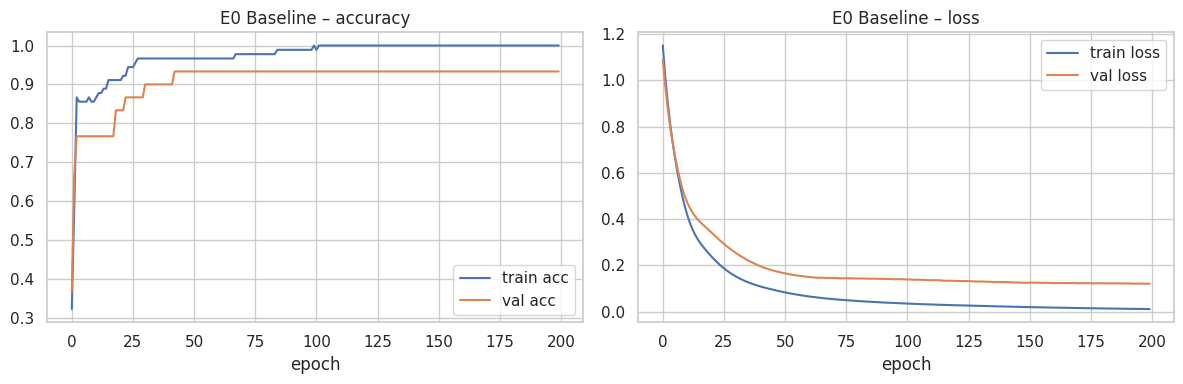

In [9]:
# (b) Overfitting check: baseline train vs val accuracy
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
h = histories[("E0: Baseline", seed0)]
ax[0].plot(h["accuracy"], label="train acc"); ax[0].plot(h["val_accuracy"], label="val acc")
ax[0].set_title("E0 Baseline – accuracy"); ax[0].set_xlabel("epoch"); ax[0].legend()
ax[1].plot(h["loss"], label="train loss"); ax[1].plot(h["val_loss"], label="val loss")
ax[1].set_title("E0 Baseline – loss"); ax[1].set_xlabel("epoch"); ax[1].legend()
plt.tight_layout(); plt.savefig("figures/fig2_baseline_overfitting.png", dpi=150); plt.show()

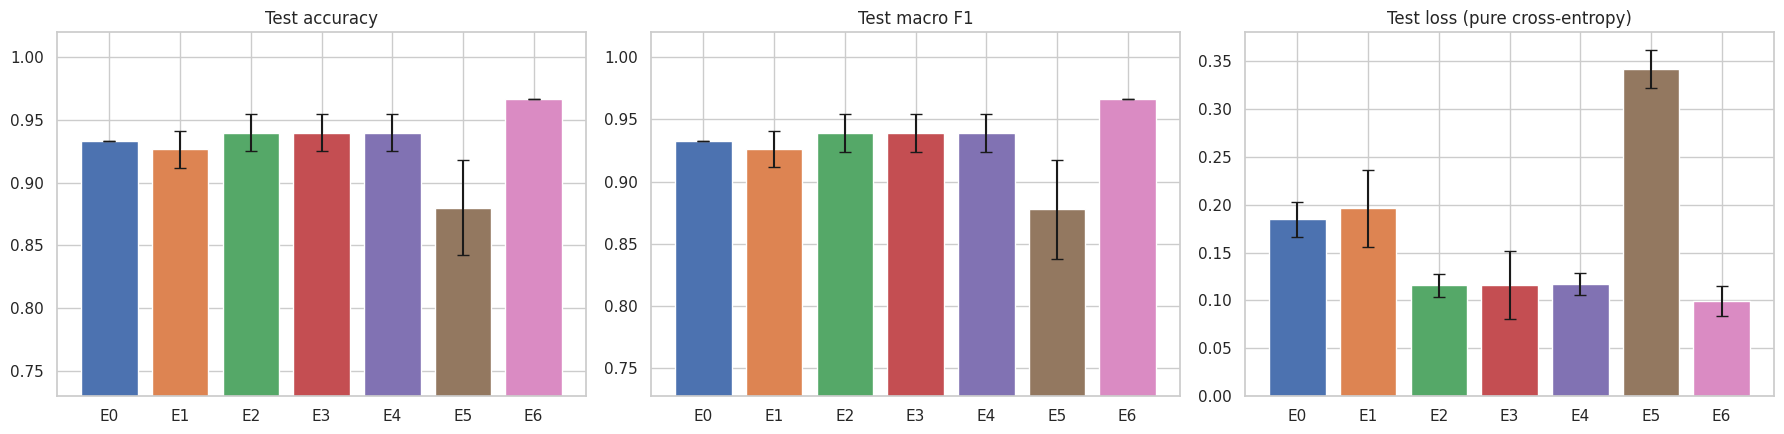

In [10]:
# (c) Metric comparison (mean ± std over seeds)
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
names = list(EXPERIMENTS); short = [n.split(":")[0] for n in names]
for ax, (col, sd, title) in zip(axes, [("test_acc","test_acc_std","Test accuracy"),
                                       ("macro_f1","macro_f1_std","Test macro F1"),
                                       ("test_loss","test_loss_std","Test loss (pure cross-entropy)")]):
    ax.bar(short, summary[col], yerr=summary[sd], capsize=4, color=sns.color_palette("deep", len(names)))
    ax.set_title(title)
    if col != "test_loss": ax.set_ylim(max(0, summary[col].min() - 0.15), 1.02)
plt.tight_layout(); plt.savefig("figures/fig3_metrics.png", dpi=150); plt.show()

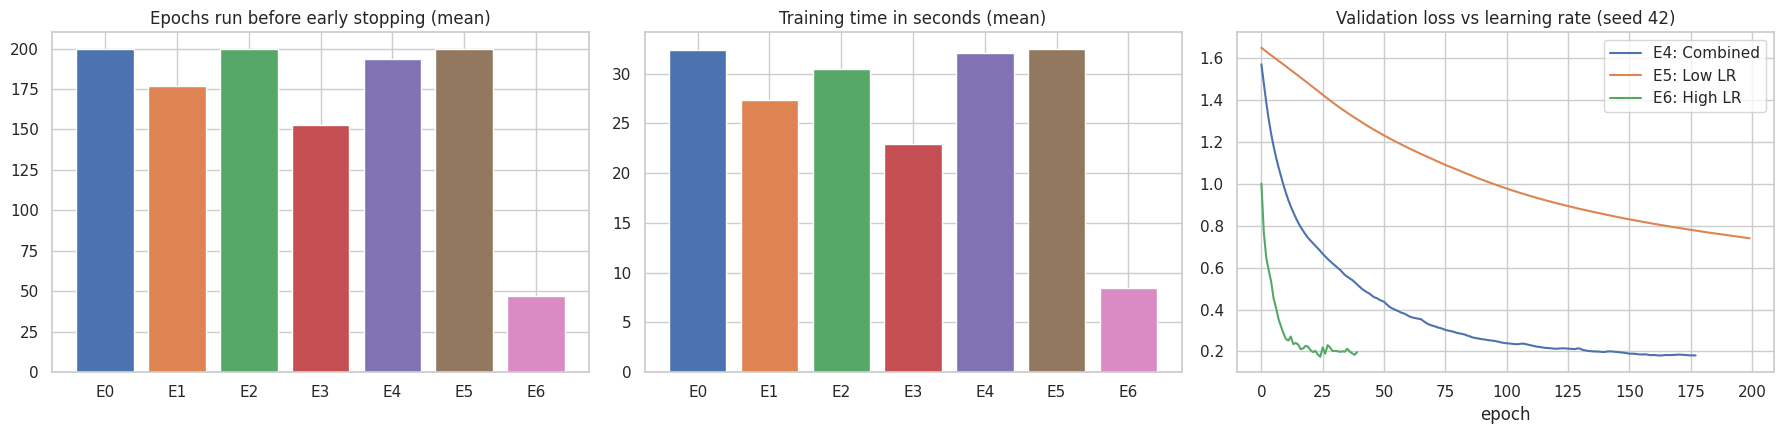

In [11]:
# (d) Training duration and learning-rate effect (E4 vs E5 vs E6)
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
axes[0].bar(short, summary.epochs_run, color=sns.color_palette("deep", len(names)))
axes[0].set_title("Epochs run before early stopping (mean)")
axes[1].bar(short, summary.train_time_s, color=sns.color_palette("deep", len(names)))
axes[1].set_title("Training time in seconds (mean)")
for name in ["E4: Combined", "E5: Low LR", "E6: High LR"]:
    axes[2].plot(histories[(name, seed0)]["val_loss"], label=name)
axes[2].set_title(f"Validation loss vs learning rate (seed {seed0})"); axes[2].set_xlabel("epoch"); axes[2].legend()
plt.tight_layout(); plt.savefig("figures/fig4_duration_lr.png", dpi=150); plt.show()

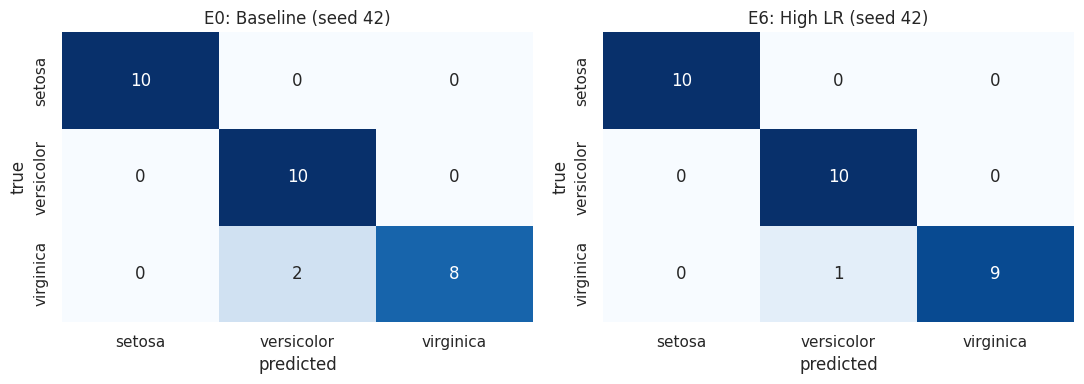

Best experiment by mean test accuracy: E6: High LR


In [12]:
# (e) Confusion matrix of the best experiment (by mean test accuracy, tie -> lower test loss)
best = summary.sort_values(["test_acc", "test_loss"], ascending=[False, True]).index[0]
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, name in zip(axes, ["E0: Baseline", best]):
    cm = confusion_matrix(y_test, preds[(name, seed0)], labels=[0, 1, 2])
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=class_names, yticklabels=class_names, ax=ax, cbar=False)
    ax.set_title(f"{name} (seed {seed0})"); ax.set_xlabel("predicted"); ax.set_ylabel("true")
plt.tight_layout(); plt.savefig("figures/fig5_confusion.png", dpi=150); plt.show()
print("Best experiment by mean test accuracy:", best)

## 6. Analysis & conclusions

**Overfitting in the baseline (E0).** The baseline reaches 100% training accuracy while validation accuracy is ~94.7%, and its pure cross-entropy gap (validation − training) is ~0.083 (train CE 0.011 vs val CE 0.094). So there is a generalization gap, but at lr = 0.001 the validation loss was still (slowly) improving up to ~epoch 198, so early stopping almost never fired before the 200-epoch cap. The overfitting is therefore mild in this setup, not a dramatic rise of validation loss.

**E1 – Initialization (He normal vs Glorot uniform).** No benefit: test accuracy 0.927 vs 0.933, test loss 0.196 vs 0.185, and a larger CE gap (0.165). One seed stopped early (epoch 84). The differences are within seed-to-seed noise, so initialization alone is not a useful lever here.

**E2 – L2 (0.01).** Cut test loss from 0.185 to 0.116 (≈37% lower) and halved the CE gap (0.083 → 0.042); accuracy rose slightly to 0.940. Cost: no reduction in training time (still ran all 200 epochs).

**E3 – Dropout (0.3).** Test loss also fell to 0.116 and accuracy to 0.940, but with higher variance across seeds (± 0.035). It stopped earlier on average (153 epochs, ≈23 s vs ≈30 s), so it was the cheapest of the lr = 0.001 runs.

**E4 – Combined (L2 + dropout).** Test loss 0.117 and accuracy 0.940: no additional gain over L2 or dropout alone on this small, easy dataset, but with the lowest loss variance (± 0.012) among the regularized runs, i.e. the most stable.

**E5 – Low learning rate (1e-4).** Clearly worse (accuracy 0.880, loss 0.343). Training accuracy was only ~0.90, so this is **under-fitting**: all runs hit the 200-epoch cap while still improving. Combined regularization is not the problem; the model simply did not have enough epochs to converge.

**E6 – High learning rate (1e-2).** Best on every metric: accuracy 0.967, macro-F1 0.967, test loss 0.099, identical across all 5 seeds, and it stopped after ~47 epochs (≈7.8 s, about 4× faster than E4). Early stopping worked as intended here (best epoch ≈ 32).

**Caveats.** (1) The test set has only 30 samples, so one sample = 3.3 accuracy points; the differences among E0–E4 in accuracy (0–2 samples) are not statistically meaningful, and test loss is the more informative metric. (2) E0, E2, E4 and E5 were still improving at the 200-epoch cap, so part of E6's advantage comes from converging within the budget, not from regularization alone. (3) E5/E6 are only compared against E4 (as required), so the learning-rate effect without regularization was not tested.

**Conclusion.** Regularization (L2 and/or dropout) improves generalization (lower test loss, smaller train–validation gap); initialization has no measurable effect; the learning rate matters most — 1e-4 under-fits within 200 epochs, while 1e-2 with L2 + dropout gave the best, most stable and fastest result. Recommended configuration: **E6 (Glorot uniform, L2 = 0.01, dropout = 0.3, lr = 0.01)**.
